In [7]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ttest_ind
from scipy.stats import mannwhitneyu
from matplotlib.lines import Line2D
from statannotations.Annotator import Annotator
import seaborn as sns


In [8]:
# Get the data 
pathB = "../data_files/tumor_volume/GE681B final.xlsx"

# Read the data into pandas
xlsB = pd.ExcelFile(pathB)

# Define function to find slope
def find_slope(data):
    return np.polyfit(data.index.values, data.values, 1)[0]

In [9]:
# Parse Excel file into one big dataframe with all data

# Parse all sheets in excel file into DataFrames and put them into a list
dfs = []
names = xlsB.sheet_names

# Start with pre-enrollment data
for i in range(0, 7):
    sheet = xlsB.parse(i, skiprows=[0, 1, 2, 3])[['Tumour ID ', 'Date of Birth', 'Cell injection date', 'MCMS \nMouse ID', "Volume (mm3)"]].truncate(after=35)
    sheet["Measurement Date"] = names[i].strip().split(" ")[-1]
    dfs.append(sheet)

# Add post-enrollment data
for i in range(7, len(names)):
    sheet = xlsB.parse(i, skiprows=[0, 1, 2, 3])[["Cohort", 'Tumour ID ', 'Date of Birth', 'Cell injection date', 'MCMS \nMouse ID', "Volume (mm3)"]].truncate(after=35)
    sheet["Measurement Date"] = names[i].strip().split(" ")[-1]
    dfs.append(sheet)

# Join all DataFrames together into one dataset, remove spaces from column names, and remove fully empty rows
temp_data = pd.concat(dfs, join="outer", ignore_index=True)
temp_data = temp_data.rename(columns=lambda x: x.strip())
temp_data.dropna(subset=["Tumour ID"], inplace=True)
temp_data.dropna(subset=["MCMS \nMouse ID"], inplace=True)

# Remove rows from initial measurement period where mice have already been moved to enrollment
temp_data.drop_duplicates(subset=['MCMS \nMouse ID', "Measurement Date"], keep="last", inplace=True)

# Export to a csv so endpoints can be manually added
temp_data.to_csv("../data_files/tumor_volume/tumor_volume_treatment_temp.csv", index=False)

In [10]:
# Import the csv with endpoints added manually from "GE681B final.xlsx"
data = pd.read_csv("../data_files/tumor_volume/tumor_volume_treatment_endpts.csv")

# Convert Measurement date to datetime
data["Measurement Date"] = pd.to_datetime(data["Measurement Date"])

# Add days post-injection column
data["Days Post-Injection"] = (data["Measurement Date"] - pd.to_datetime(data["Cell injection date"])).dt.days

# Add cohort to data pre-enrollment
mice_cohorts = data.drop_duplicates(subset=["MCMS \nMouse ID"], keep="last", ignore_index=True)[["MCMS \nMouse ID", "Cohort"]].dropna()
mice_cohorts["Cohort"] = mice_cohorts["Cohort"].str.split(" ").str[-1].str.split("-").str[-1]
mice_cohorts.set_index("MCMS \nMouse ID", inplace=True)
mouse_cohorts = mice_cohorts.to_dict()

data["Cohort"] = data["MCMS \nMouse ID"].apply(lambda x: mouse_cohorts["Cohort"].get(x))

# Add treatment window to dataframe 
treatment = {"STG139-X5": "14-Apr-22", "STG201-X5": "24-Mar-22", "IC07-X5": "31-Mar-22", "AB040-X5": "31-Mar-22"}

data["Treatment Start"] = pd.to_datetime(data["Tumour ID"].apply(lambda x: treatment.get(x)), format="%d-%b-%y")
data["Treatment End"] = (data["Treatment Start"] + pd.to_timedelta(6, unit="W"))
data["Treatment Start Delta"] = (data["Treatment Start"] - pd.to_datetime(data["Cell injection date"])).dt.days
data["Treatment End Delta"] = (data["Treatment End"] - pd.to_datetime(data["Cell injection date"])).dt.days

# Remove datapoints where the tumor volume is the same between weeks (ie measurements have stopped)
removed = data.drop_duplicates(subset=['MCMS \nMouse ID', "Volume (mm3)"], keep="first", inplace=False)
zeros = data[data["Volume (mm3)"] == 0]
filtered = pd.concat([removed, zeros], ignore_index=True).drop_duplicates(subset=["MCMS \nMouse ID", "Measurement Date"], keep='first')

# Save final secondary tumor volume dataframe
filtered.to_csv("../data_files/tumor_volume/secondary_cohort_tumor_volume.csv")

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_30760/3039307520.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data["Measurement Date"] = pd.to_datetime(data["Measurement Date"])


/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_30760/2336935461.py:52: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels=list(grouped_df.index), fontsize=9)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_30760/2336935461.py:52: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels=list(grouped_df.index), fontsize=9)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_30760/2336935461.py:52: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels=list(grouped_df.index), fontsize=9)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_30760/2336935461.py:52: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after s

STG139-X5
                  mean        sem
cohort                           
Untreated    42.903424  32.900697
Paclitaxel   40.023340  14.182139
Carboplatin  46.754034  10.750780
STG139-X5 Untreated vs Paclitaxel: t-statistic (individual, one-tailed) = 0.08038815508221889, p-value = 0.4698949581791334
STG139-X5 Untreated vs Carboplatin: t-statistic (individual, one-tailed) = -0.11124866320640543, p-value = 0.5416110311494271
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Untreated vs. Paclitaxel: Custom statistical test, P_val:4.699e-01
Untreated vs. Carboplatin: Custom statistical test, P_val:5.416e-01
STG201-X5
                  mean       sem
cohort                          
Untreated    83.245633  9.883081
Paclitaxel   24.463468  5.484866
Carboplatin   1.266671  2.207170
STG201-X5 Untreated vs Paclitaxel: t-statistic (individual, one-tail

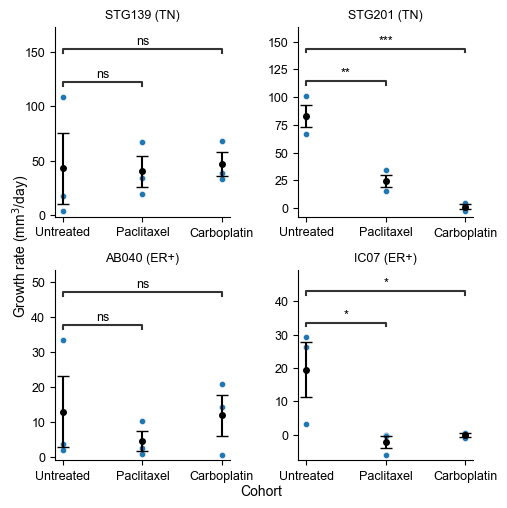

In [11]:
# Graph tumor growth at final 2 weeks of treatment; standard error of mean instead of standard deviation for error
# Set up figure with subplots
fig, axes = plt.subplots(2, 2, sharex=True, sharey=False, figsize=(5, 5))
counter = 0

# Plot tumor volume
tumor_ids = ["STG139-X5", "STG201-X5", "AB040-X5", "IC07-X5"]
cohorts = filtered["Cohort"].unique()
cancer_type = {"STG139": "TN", "STG201": "TN", "AB040": "ER+", "IC07": "ER+"}

for item, ax in zip(tumor_ids, axes.ravel()): 
    slopes = {"cohort":[], "mouse":[], "slope":[]}
    for cohort in cohorts:
        for mouse in filtered.loc[((filtered["Tumour ID"] == item) & (filtered["Cohort"] == cohort))]["MCMS \nMouse ID"].unique():
            dataset = filtered.loc[(filtered["Tumour ID"] == item) & (filtered["MCMS \nMouse ID"] == mouse) & (filtered["Volume (mm3)"] > 0) & (filtered["Days Post-Injection"] <= filtered["Treatment End Delta"])].copy()
            dataset = dataset.iloc[(dataset["Treatment End Delta"]-dataset['Days Post-Injection']).abs().argsort()[:2]]
            dataset.set_index("Days Post-Injection", inplace=True)
            dataset["slope"] = dataset["Volume (mm3)"].rolling(2).apply(find_slope, raw=False)
            dataset.dropna(inplace=True)
            slopes["cohort"].append(cohort)
            slopes["mouse"].append(mouse)
            slopes["slope"].append(dataset.iloc[0]["slope"])
    slope_df = pd.DataFrame(slopes)
    grouped_df = slope_df.groupby(["cohort"])["slope"].agg(["mean", "sem"]).sort_values("cohort", ascending = False)
    print(item)
    print(grouped_df)

    # Calculate significance and print results (one-sided individual student's t test to see if untreated slope is greater than treated)
    t_stat_UvP, p_val_UvP = ttest_ind(slope_df[slope_df["cohort"] == "Untreated"]["slope"], slope_df[slope_df["cohort"] == "Paclitaxel"]["slope"], alternative="greater")
    t_stat_UvC, p_val_UvC = ttest_ind(slope_df[slope_df["cohort"] == "Untreated"]["slope"], slope_df[slope_df["cohort"] == "Carboplatin"]["slope"], alternative="greater")
    print(f"{item} Untreated vs Paclitaxel: t-statistic (individual, one-tailed) = {t_stat_UvP}, p-value = {p_val_UvP}")
    print(f"{item} Untreated vs Carboplatin: t-statistic (individual, one-tailed) = {t_stat_UvC}, p-value = {p_val_UvC}")

    strip_args = {
        "x": "cohort",
        "y": "slope",
        "data": slope_df,
        "zorder": 0.5,
        "order": ["Untreated", "Paclitaxel", "Carboplatin"],
        "dodge": True
    }
    sns.set_context(rc={"font.size":9})

    # Construct the graph
    sns.scatterplot(ax=ax, 
                    data=slope_df, 
                    x="cohort", 
                    y="slope", 
                    s=20)
    ax.errorbar(grouped_df.index, grouped_df["mean"], yerr=grouped_df["sem"], capsize=4, fmt="o", label='Mean ± SEM', color='black', markersize=4)
    ax.set_title(f"{item[:-3]} ({cancer_type[item[:-3]]})", fontsize=9)
    ax.set_xticklabels(labels=list(grouped_df.index), fontsize=9) 
    ax.tick_params(axis='y', labelsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_ylim(top=slope_df['slope'].max() * 1.6)
    ax.set(xlabel=None, ylabel=None)
    ax.tick_params(labelbottom=True)
    annot = Annotator(
        ax=ax,
        pairs=[
            ("Untreated", "Carboplatin"),
            ("Untreated", "Paclitaxel")
        ],
        **strip_args,
        plot="stripplot"
    )
    annot.configure(test=None, text_format='star', loc='inside', verbose=2) 
    annot.set_pvalues([p_val_UvC, p_val_UvP])
    annot.annotate()

    counter += 1

fig.text(0.5, 0.01, "Cohort", ha='center', va='center', fontsize=10)
fig.text(0.02, 0.5, "Growth rate (mm$^{3}$/day)", ha='center', va='center', rotation='vertical', fontsize=10) 
plt.tight_layout()
plt.rcParams['font.family'] = 'Arial'
plt.savefig(f"../visualizations/tumor_growth/tumor_response.svg", bbox_inches="tight")
plt.show()

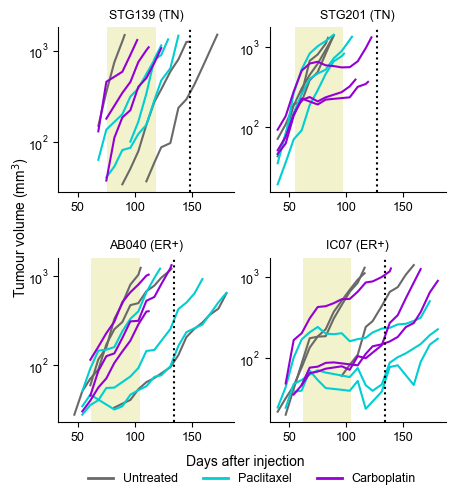

['STG139-X5', 'STG201-X5', 'AB040-X5', 'IC07-X5']

In [12]:
# Graph tumor volume, log scale, repeat endpoints removed, subplots

# Plot tumor volume
tumor_ids = ['STG139-X5', 'STG201-X5', 'AB040-X5', 'IC07-X5']
cohorts = filtered["Cohort"].unique()

model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}

colors = [["dimgrey", "dimgrey", "dimgrey"], ["darkturquoise", "darkturquoise", "darkturquoise"], ["darkviolet", "darkviolet", "darkviolet"]]
custom_lines = [Line2D([0], [0], color="dimgrey", lw=2), 
                Line2D([0], [0], color="darkturquoise", lw=2),
                Line2D([0], [0], color="darkviolet", lw=2)]
fig, axes = plt.subplots(2, 2, sharex=True, figsize=(5, 5))

for item, ax in zip(tumor_ids, axes.ravel()): 
    legend = []
    model = item.split("-")[0]
    for cohort, colorset in zip(cohorts, colors):
        for mouse, color in zip(filtered.loc[((filtered["Tumour ID"] == item) & (filtered["Cohort"] == cohort))]["MCMS \nMouse ID"].unique(), colorset):
            dataset = filtered.loc[(filtered["Tumour ID"] == item) & (filtered["MCMS \nMouse ID"] == mouse) & (filtered["Volume (mm3)"] > 0)]
            ax.plot(dataset["Days Post-Injection"], dataset["Volume (mm3)"], color=color, label="{item}")
            if mouse in ["M00021187", "M00021186", "M00021189"]:
                legend.append(f"{cohort}")
    ax.tick_params(axis="both")
    ax.axvspan(dataset["Treatment Start Delta"].iloc[0], dataset["Treatment End Delta"].iloc[0], facecolor='y', alpha=0.2)
    ax.set_yscale("log")
    ax.set_title(f"{model} ({model_type[model]})", fontsize=9)
    ax.spines[['right', 'top']].set_visible(False)
    ax.tick_params(labelbottom=True)
    ax.yaxis.minorticks_off()
    ax.axvline(x=dataset["Treatment End Delta"].iloc[0]+30, color='black', linestyle=':')

fig.text(0.5, 0.03, "Days after injection", ha='center', va='center', fontsize=10)
fig.text(0.05, 0.5, "Tumour volume (mm$^{3}$)", ha='center', va='center', rotation='vertical', fontsize=10) 
plt.rcParams['font.family'] = 'Arial'
plt.legend(handles=custom_lines, labels=legend, loc="lower center", bbox_to_anchor=(-0.1, -0.45), fontsize=9, ncol=4, frameon=False)
plt.subplots_adjust(top=0.9, hspace=0.4)
plt.savefig(f"../visualizations/tumor_growth/tumor_growth_curves.svg", bbox_inches="tight")
plt.show()

tumor_ids
